In [1]:
import sys
sys.path.insert(0, 'C:/Users/au646858/OneDrive - Aarhus Universitet/Documents/_repositories/sea-anemone/app')
from temframe import TEMframe
from session import Session

C:\Users/au646858/OneDrive - Aarhus Universitet/Documents/_repositories/sea-anemone/app\temframe.py:19: UserWarning: The default iteration cap for TEMframe inversion has been reduced to 10 to speed up testing. Change it back to 50 for production runs.
  warnings.warn("The default iteration cap for TEMframe inversion has been reduced to 10 to speed up testing. Change it back to 50 for production runs.", UserWarning)


In [2]:
df = TEMframe.from_usfzip("C:/Users/au646858/Downloads/Eliye_Spring_1_usf.zip")

In [5]:
from panels import *

m1 = Map(data=df.overview())
m1.settings.plot_by = 'doi'
m1.render()

In [4]:
from anemone.inversion import LogResistivity
import torch

res_start = LogResistivity.smooth(torch.ones(31)*10, torch.cumsum(torch.logspace(0,1, 30), dim=0))
dfmod,dfdat,dfsite = df.invert(res_start)

001	Data misfit:	20.69	Vertical misfit:	0.00	Horizontal misfit:	0.00	Total misfit:	9.13	Step size:	1.10	Last iteration time:	8.61

002	Data misfit:	11.93	Vertical misfit:	0.02	Horizontal misfit:	0.02	Total misfit:	5.26	Step size:	1.10	Last iteration time:	7.32

003	Data misfit:	6.12	Vertical misfit:	0.06	Horizontal misfit:	0.04	Total misfit:	2.71	Step size:	1.28	Last iteration time:	6.82

004	Data misfit:	2.79	Vertical misfit:	0.15	Horizontal misfit:	0.09	Total misfit:	1.27	Step size:	1.28	Last iteration time:	7.28

005	Data misfit:	1.97	Vertical misfit:	0.20	Horizontal misfit:	0.12	Total misfit:	0.93	Step size:	1.28	Last iteration time:	7.08

006	Data misfit:	1.75	Vertical misfit:	0.25	Horizontal misfit:	0.13	Total misfit:	0.85	Step size:	1.46	Last iteration time:	6.74

007	Data misfit:	1.63	Vertical misfit:	0.33	Horizontal misfit:	0.15	Total misfit:	0.82	Step size:	1.46	Last iteration time:	7.26

008	Data misfit:	1.50	Vertical misfit:	0.37	Horizontal misfit:	0.15	Total misfit:	0.78	S

In [15]:
sesh = Session(data=dfdat, models=dfmod, site=dfsite, forwards=dfdat.forward_operators)

In [6]:
sesh2 = Session.from_folder('anemone_backup/')

In [14]:
class Map2(Map):
    def render(self):
        if self.dataframe is None: return self.empty_render()
        if self.settings.plot_by in self.dataframe.columns:
            fig = px.scatter_map(self.dataframe, lat="latitude", lon="longitude", zoom=self.settings.zoom, color=self.settings.plot_by, color_continuous_scale='turbo')
        else:
            fig = px.scatter_map(self.dataframe, lat="latitude", lon="longitude", zoom=self.settings.zoom, color_discrete_sequence=[self.settings.color])
        fig.update_layout(map_style="white-bg",
            map_layers=[
                {
                    "below": 'traces',
                    "sourcetype": "raster",
                    "sourceattribution": "Google Earth (C)",
                    "source": ['https://mt1.google.com/vt/lyrs=s&x={x}&y={y}&z={z}']
                }])
        if self.highlighted is not None:
            highlight_trace = px.scatter_map(self.dataframe[self.dataframe.index == self.highlighted], lat="latitude", lon="longitude", color_discrete_sequence=[self.settings.highlight_color])
            highlight_trace.update_traces(marker=dict(size=14))
            for trace in highlight_trace.data:
                fig.add_trace(
                    trace
                )
        fig.update_layout(margin={"r":0,"t":0,"l":0,"b":0},
                          modebar=dict(add=['drawline', 'drawopenpath', 'eraseshape'], remove=['zoomIn', 'zoomOut']),
                          newshape=dict(line_color='cyan', line_width=3),
                          dragmode='select')
        return fig    

In [17]:
m1 = Map2(data=sesh2.site)
m1.settings.plot_by = 'doi'

In [ ]:
from dash import Dash, dcc, html, Output, Input, State

app = Dash()
app.layout = m1.initialize()

@app.callback(
    Output('map', 'relayoutData'),
    Input('map', 'relayoutData'),
    State('map', 'figure'),
    prevent_initial_call=True
)
def print_selected(selected_data, fig):
    # print(selected_data)
    if 'shapes' in fig['layout']:
        print(fig['layout']['shapes'])
    return selected_data

app.run(debug=True, use_reloader=False)  # Turn off reloader if inside Jupyter

[{'editable': True, 'visible': True, 'showlegend': False, 'legend': 'legend', 'legendgroup': '', 'legendgrouptitle': {'text': '', 'font': {'weight': 'normal', 'style': 'normal', 'variant': 'normal', 'lineposition': 'none', 'textcase': 'normal', 'shadow': 'none'}}, 'legendrank': 1000, 'label': {'text': '', 'texttemplate': '', 'texttemplatefallback': '-'}, 'xref': 'paper', 'yref': 'paper', 'layer': 'above', 'opacity': 1, 'line': {'color': 'cyan', 'width': 3, 'dash': 'solid'}, 'type': 'line', 'x0': 0.4813477737665463, 'y0': 0.22444444444444445, 'x1': 0.5018050541516246, 'y1': 0.6555555555555556}]
[{'editable': True, 'visible': True, 'showlegend': False, 'legend': 'legend', 'legendgroup': '', 'legendgrouptitle': {'text': '', 'font': {'weight': 'normal', 'style': 'normal', 'variant': 'normal', 'lineposition': 'none', 'textcase': 'normal', 'shadow': 'none'}}, 'legendrank': 1000, 'label': {'text': '', 'texttemplate': '', 'texttemplatefallback': '-'}, 'xref': 'paper', 'yref': 'paper', 'layer':

In [4]:
df.forward_operators[1].save('forward_operator_0.json')

In [5]:
from anemone.forwards import Forward

fwr1 = Forward.load('forward_operator_0.json')

In [6]:
import torch
rho = torch.tensor([2.0, 3.0, 4.0])*10
thick = torch.tensor([1.0, 2.0])*10
dbdt = fwr1(rho, thick)

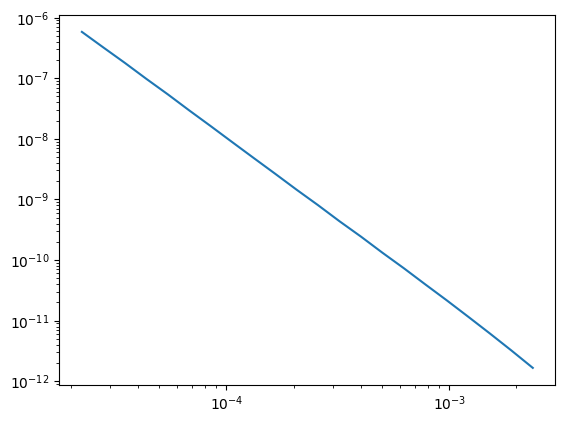

In [7]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure()
plt.loglog(fwr1.times, dbdt)

In [8]:
dbdt_panel.settings

dbdtSoundingSettings(id='sounding', _settings_schema={'type': 'object', 'required': ['id'], 'properties': {'lm_color': {'type': 'string', 'default': '#ff0000'}, 'hm_color': {'type': 'string', 'default': '#2D81FF'}, 'lm_factor': {'type': 'number', 'default': 20.0}, 'hm_factor': {'type': 'number', 'default': 1.0}, 'plot_error': {'type': 'boolean', 'default': False}, 'x_axis': {'enum': ['time', 'gate_id'], 'default': 'time'}, 'dbdt_max': {'type': 'number', 'default': -3}, 'dbdt_min': {'type': 'number', 'default': -12}}, '$schema': 'http://json-schema.org/draft-06/schema#'}, title=None, lm_color='#ff0000', hm_color='#2D81FF', lm_factor=20.0, hm_factor=1.0, plot_error=False, x_axis='time', dbdt_max=-3, dbdt_min=-12)

In [11]:
dbdt_panel = dbdtSounding(dataframe=sesh2.data)
dbdt_panel.settings.x_axis = 'misfit'
fig = dbdt_panel.render()
fig.update_layout(xaxis_type='log')